# Week 9 - spaCy from the beginning

**Social and Cultural Data Analytics**

How do we turn a passage of text into information we can analyse in pandas?
Start with one short passage. Inspect each result before moving on.

- Create a spaCy document and inspect its tokens.
- Read lemmas, word classes, stop-word and punctuation flags.
- Find names of people, organisations and places.
- Put those results into DataFrames.
- Use pandas to compare descriptions of two London venues.

Use the module Python environment, which includes spaCy and its small
English model. 

If you're having issues with your local Python environment, you can try Google Colab.

## 1. Load spaCy and create a document

**spaCy is a Python library for processing human language.** We can use it
to identify words, add linguistic information and find names in a text.
First, make the library available to Python.

In [ ]:
import spacy

Now load the small English language package. It supplies language rules
and components trained on example texts. We are using an existing model,
not training one. We choose `nlp` as the name for our text processor.

`en_core_web_sm` is the package name: English, general linguistic features,
written web text, small version. `load()` loads the installed package;
it does not yet process our text.

In [ ]:
nlp = spacy.load("en_core_web_sm")

Start with this short, invented example about a London venue. `text` is an ordinary Python string.

In [ ]:
text = 'Alice visited the Horniman Museum in London. She enjoyed its musical instruments.'
print(text)

Pass the string to `nlp` and store the result as `doc`. Compare their types.

In [ ]:
doc = nlp(text)
print(type(text))
print(type(doc))

A `Doc` keeps the original text together with spaCy's results. It contains tokens we can inspect individually. Processing has not removed words or punctuation.

**Your turn.** Print `doc.text`. Why does it look like the original string even though `doc` has a different type?

In [ ]:
# Write your code here.

**Your notes:**

## 2. Look inside the Doc

A **token** is one occurrence identified by the tokeniser. Words and
punctuation can both be tokens. `doc[0]` selects the first token;
indexing starts at zero. A string's first item is a character, whereas
a Doc's first item is a Token.

In [ ]:
token = doc[0]
print(token.text)
print(type(token))
print("Number of tokens:", len(doc))

A `for` loop visits each token in order. The indented line runs once per token. On each pass, `token` refers to a different occurrence.

If you need a reminder of for loops, take a look at this weeks additional worksheet on Keats: `w09_loops_and_conditionals_worksheet.ipynb`  

In [ ]:
for token in doc:
    print(token.text)

Tokens have **attributes**: pieces of information read using dot notation.
These flags return `True` or `False`. They describe tokens; they do not
remove them.

In [ ]:
token = doc[2]
print(token.text)
print("Letters only:", token.is_alpha)
print("Stop word:", token.is_stop)
print("Punctuation:", token.is_punct)

**Your turn.** Select the final token with `doc[-1]`. Print its text and `is_punct`. Why is it included in `len(doc)`?

In [ ]:
# Write your code here.

**Your notes:**

**Your turn.** Change the loop above to print each token's text and `is_stop`. Does a stop-word flag mean we must remove the word?

In [ ]:
# Write your code here.

**Your notes:**

## 3. Read linguistic annotations

A **lemma** is a proposed base form: for example, a plural noun may be
linked to its singular form. These predictions are available because we
processed the text with the English pipeline.

In [ ]:
for token in doc:
    print(token.text, token.lemma_)

`text` gives the original form; `lemma_` gives the readable lemma. The final underscore is part of the attribute name. Reading a lemma does not replace the original word.

**Your turn.** Find two words whose lemmas differ from their original forms. What distinction has been removed?

**Your notes:**

**Part of speech (POS)** describes a token's grammatical use. `NOUN` means common noun, `PROPN` proper noun, `VERB` verb, `ADJ` adjective and `PUNCT` punctuation.

In [ ]:
for token in doc:
    print(token.text, token.pos_)

Use `spacy.explain()` to look up a label rather than memorising every abbreviation.

In [ ]:
print(spacy.explain("PROPN"))

**Your turn.** Create a Doc for `They paint the walls.` and print each token with its POS. Then change the text to `The paint is blue.`. Does `paint` keep the same grammatical role?

In [ ]:
# Write your code here.

**Your notes:**

## 4. Find people, organisations and places

**Named entity recognition (NER)** predicts names and their types.
`doc.ents` gives the entity mentions found in this passage. Each entity
is a **span**: it can cover several tokens.

In [ ]:
for entity in doc.ents:
    print(entity.text, entity.label_)

`entity.text` is the named passage; `label_` is its predicted category. `PERSON` means a person, `ORG` an organisation and `GPE` a country, city or other geopolitical place. These are linguistic labels, not our cultural-venue categories.

In [ ]:
print(spacy.explain("GPE"))

**Your turn.** Which recognised name contains more than one token? What is the difference between that entity span and one Token?

**Your notes:**

**Your turn.** Process `London` on its own and print its entities. Then try a short sentence with a person, organisation and place of your choice. Read the result: are the labels plausible?

In [ ]:
# Write your code here.

**Your notes:**

## 5. From annotations to pandas

We can now turn the information we inspected into a familiar table.
**One row will represent one token occurrence.** Begin with pandas.

In [ ]:
import pandas as pd

First make a dictionary for **one** token. The keys name the columns we want; the values come from that token's attributes.

In [ ]:
token = doc[1]
row = {"word": token.text, "lemma": token.lemma_,
       "pos": token.pos_, "is_stop": token.is_stop,
       "is_punct": token.is_punct}
row

Now collect the same information for every token. Start the list once, before the loop. `.append(row)` adds one dictionary to it on each pass.

In [ ]:
rows = []
for token in doc:
    row = {"word": token.text, "lemma": token.lemma_,
           "pos": token.pos_, "is_stop": token.is_stop,
           "is_punct": token.is_punct}
    rows.append(row)

The loop has finished. Create the DataFrame **after** it. Dictionary keys become column names; each dictionary becomes one row.

In [ ]:
tokens = pd.DataFrame(rows)
tokens

This table is data you can analyse with pandas. Start by counting the POS labels.

In [ ]:
tokens["pos"].value_counts()

For a vocabulary count, choose whether to exclude punctuation and stop words. Do it in two steps so we can see each decision. `~` reverses a Boolean flag, keeping rows where that flag is false.

In [ ]:
word_tokens = tokens[~tokens["is_punct"]]
content = word_tokens[~word_tokens["is_stop"]]
content["lemma"].value_counts()

**Your turn.** Compare `tokens` and `content`. Name two removed forms. What information would be lost if we kept only the filtered version?

**Your notes:**

**Your turn.** Add `"is_alpha": token.is_alpha` to the row dictionary in the collecting loop. Rerun that loop and the DataFrame cell. What new column appears?

**Your notes:**

**A separate table for named entities.** Here one row means an entity
mention, not a token. Use the collecting pattern to store `entity.text`
under `name` and `entity.label_` under `label`, then build `entities`.

**Your turn.** Create `entity_rows = []`, loop over `doc.ents`, append one dictionary per entity, and create `entities = pd.DataFrame(entity_rows)` after the loop. Print the table and count its `label` values.

In [ ]:
# Write your code here.

**Your notes:**

## 6. Follow-up: compare two London descriptions

We have reached the important bridge: annotations → tables → analysis.
Use two real articles to ask **which common nouns characterise a museum
description and a music-venue description**.

The next provided cell locates the supplied files from the module folder
or uploaded Colab files. Run it once; the NLP steps follow below.

In [ ]:
from pathlib import Path

# PROVIDED FILE LOCATOR: locates supplied CSVs without loading or analysing them.
def teaching_file(name):
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent / "data" / name,
                          parent / "weeks/week-09/data" / name, parent / name):
            if candidate.is_file():
                return candidate
    raise FileNotFoundError(f"Cannot find {name}. Extract the Week 9 download, or upload the supplied data files in Colab.")

In [ ]:
articles = pd.read_csv(teaching_file("w09_articles.csv"))
articles[["title", "opening_sentence"]]

Select the full Horniman Museum article and process it. We will collect just the attributes needed for this comparison.

In [ ]:
museum_article = articles[articles["title"] == "Horniman Museum"].iloc[0]
museum_doc = nlp(museum_article["text"])
museum_rows = []
for token in museum_doc:
    row = {"word": token.text, "lemma": token.lemma_.lower(), "pos": token.pos_}
    museum_rows.append(row)
museum_tokens = pd.DataFrame(museum_rows)
museum_tokens.head()

Now select The Jazz Cafe. The document changes; the collecting pattern stays the same.

In [ ]:
music_article = articles[articles["title"] == "The Jazz Cafe"].iloc[0]
music_doc = nlp(music_article["text"])

**Your turn.** Repeat the collecting pattern for `music_doc`. Call the list `music_rows` and the resulting DataFrame `music_tokens`, with the same word, lemma and pos columns.

In [ ]:
# Write your code here.

**Your notes:**

Select common nouns (`NOUN`) from each table, then count their lowercase lemmas. Proper names (`PROPN`) are a different category.

In [ ]:
museum_nouns = museum_tokens[museum_tokens["pos"] == "NOUN"]["lemma"].value_counts()
music_nouns = music_tokens[music_tokens["pos"] == "NOUN"]["lemma"].value_counts()
comparison = pd.DataFrame({"Horniman Museum": museum_nouns,
                           "The Jazz Cafe": music_nouns}).fillna(0)
comparison.loc[["collection", "instrument", "music", "venue"]]

The Series are aligned by their lemma names. `.fillna(0)` marks a lemma not counted in the other article as zero. We built the table from all noun counts, then selected four terms to inspect.

The articles differ in length. Convert each column to a percentage of **all noun occurrences in that article**, rather than comparing only its raw counts.

In [ ]:
percentages = 100 * comparison / comparison.sum()
percentages.loc[["collection", "instrument", "music", "venue"]].round(1)

To read the source again, use `print(museum_article["text"])` or `print(music_article["text"])`.

**Your turn.** Which article gives a greater share of its common-noun vocabulary to collections and instruments? Which gives more to music and venues? Find a passage supporting one interpretation. What can this tell us about the descriptions, rather than the activities or visitors of every venue?

**Your notes:**

### 6a. Prepared example: compare venue categories

The lecture compared **Museum**, **Theatre** and **Music venue** articles.
Do those groups emphasise different things? Here we use the larger
collection of 439 articles, rather than just the two above.

Run these prepared steps from the lecture to make one row per selected word.
We count lowercase alphabetic **word forms**, excluding stop words. We
are not restricting this comparison to nouns or grouping forms as lemmas.
The original texts stay in `corpus`.

In [2]:
corpus = pd.read_csv(teaching_file("w09_corpus.csv.gz"))
article_tokens = []
for text in corpus["text"]:
    doc = nlp.tokenizer(text)
    article_tokens.append(list(doc))
corpus["token"] = article_tokens
print(corpus["category"].value_counts())

category
Theatre        174
Museum         166
Music venue     99
Name: count, dtype: int64


Each article now has a list of tokens. `.explode("token")` puts each token on its own row and repeats the article's other columns alongside it.

In [3]:
category_words = corpus.explode("token")
display(category_words[["title", "category", "token"]].head(6))

,title,category,token
0,100 Club,Music venue,The
0,100 Club,Music venue,100
0,100 Club,Music venue,Club
0,100 Club,Music venue,is
0,100 Club,Music venue,a
0,100 Club,Music venue,music


Collect a True/False decision and a lowercase spelling for each token. Keep only the alphabetic tokens that are not stop words.

In [4]:
keep = []
word_text = []
for token in category_words["token"]:
    keep.append(token.is_alpha and not token.is_stop)
    word_text.append(token.lower_)
category_words["word"] = word_text
category_words = category_words[keep]
display(category_words[["title", "category", "word"]].head(6))

,title,category,word
0,100 Club,Music venue,club
0,100 Club,Music venue,music
0,100 Club,Music venue,venue
0,100 Club,Music venue,located
0,100 Club,Music venue,oxford
0,100 Club,Music venue,street


One row in `corpus` is an article; one row in `category_words` is a counted word occurrence. Each article has a supplied primary category. A venue can have other functions too.

**Which words are most frequent in each category?** The same pandas selection and count run once per group. The table shows frequency ranks, not matched words across each row.

In [5]:
categories = ["Museum", "Theatre", "Music venue"]
top_by_category = {}
for category in categories:
    group_words = category_words[category_words["category"] == category]["word"]
    top_by_category[category] = group_words.value_counts().head(5).index
display(pd.DataFrame(top_by_category, index=range(1, 6)))

,Museum,Theatre,Music venue
1,museum,theatre,london
2,house,starring,st
3,london,london,church
4,collection,new,stadium
5,gallery,directed,venue


### 6b. Compare the same words with a plot

Choose words associated with collections, performances and venues, plus
`building`, which might be shared. Compare their **percentages**, because
the categories contain different numbers and lengths of articles.

Calculate each word's share of **all counted words in that category**
before selecting the four words to show. `normalize=True` makes the
proportions; multiplying by 100 makes percentages.

In [6]:
shares_by_category = {}
for category in categories:
    group_words = category_words[category_words["category"] == category]["word"]
    shares_by_category[category] = group_words.value_counts(normalize=True) * 100
category_percentages = pd.DataFrame(shares_by_category).fillna(0)
chosen_words = ["collection", "production", "club", "building"]
category_comparison = category_percentages.reindex(chosen_words).fillna(0)
display(category_comparison.round(3))

,Museum,Theatre,Music venue
word,,,
collection,0.658,0.019,0.010
production,0.021,0.411,0.025
club,0.014,0.056,0.480
building,0.505,0.485,0.451


Each column now represents a category and each row the same word. `.reindex(chosen_words)` selects those rows in the order we chose. A zero means the form was not counted in that category. `collection` and `collections` remain separate forms here.

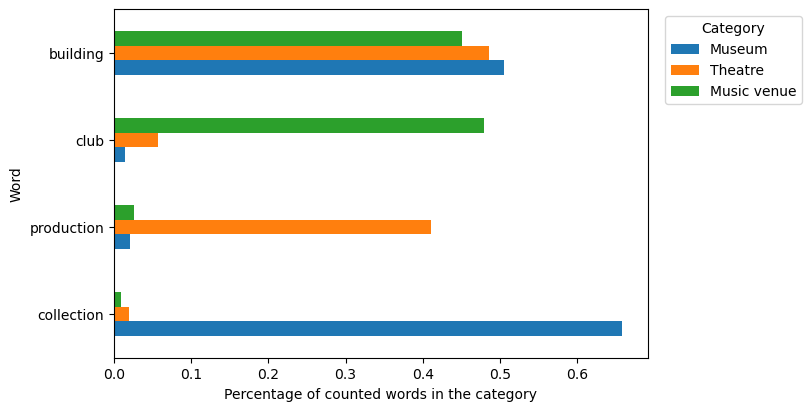

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
category_comparison.plot.barh(ax=ax)
ax.set_xlabel("Percentage of counted words in the category")
ax.set_ylabel("Word")
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

`collection`, `production` and `club` are concentrated in different groups.
`building` has a similar share across all three: the descriptions share
architectural vocabulary as well as differing in cultural activities.

These percentages compare article vocabulary, not numbers of venues,
performances or visitors. Longer articles still contribute more words;
dividing by word totals does not give each article equal weight.

**Your turn.** Change one word in chosen_words and rerun the comparison and plot. What did you expect to see? Explain the pattern, name its denominator, and read one matching article before interpreting it.

**Your notes:**

## 7. Try one text of your own

Start with a single passage. You can first replace the string in section 1
with a short text you choose, then rerun the examples. Once that is familiar,
load a file with one of these alternatives.

**CSV:** one row per text. Replace `text` with your text column's name if needed.

```python
own_data = pd.read_csv("my_texts.csv")
own_doc = nlp(own_data["text"].iloc[0])
```

**TXT:**

```python
from pathlib import Path
own_text = Path("my_text.txt").read_text(encoding="utf-8")
own_doc = nlp(own_text)
```

Repeat the token loop, entity loop and table-building pattern using
`own_doc`. Choose a pandas count or selection that helps answer a question
about this text. No automatic file detection or extra loading framework
is needed.

**Your turn.** Load or type your text and build a small table from its annotations. State the source, what one row represents, one result and a passage that helps explain it.

In [ ]:
# Write your code here.

**Your notes:**

## Further reading and sources

Main guide: Tuomo Hiippala's University of Helsinki materials,
[Processing texts using spaCy](https://applied-language-technology.mooc.fi/html/notebooks/part_ii/03_basic_nlp.html)
and [Managing textual data using pandas](https://applied-language-technology.mooc.fi/html/notebooks/part_ii/06_managing_data.html).
Supplement: Ines Montani's [spaCy course, Chapter 1](https://course.spacy.io/en/chapter1/),
especially documents/tokens, lexical attributes and predicted annotations.
These resources explain the ideas in more depth. Their course materials
are available under CC BY-NC licences; see the linked sites for details.
The short visitor example and exercises here are newly written.

London article text: Wikipedia contributors, CC BY-SA 4.0. The supplied
article rows retain their source URLs and revision IDs. See `data/README.md`.
Alice's visit in the opening example is fictional, not a visitor record.